In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import numpy as np

In [2]:
cifar10 = tf.keras.datasets.cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

In [4]:
# dataset_dir = "/content/drive/MyDrive/datasets/cifar-10"

# if not os.path.exists(dataset_dir):
#     os.makedirs(dataset_dir, exist_ok=True)

#     (x_train, y_train), (x_test, y_test) = (
#         tf.keras.datasets.cifar10.load_data()
#     )

#     import numpy as np

#     np.savez_compressed(
#         os.path.join(dataset_dir, "cifar10.npz"),
#         x_train=x_train,
#         y_train=y_train,
#         x_test=x_test,
#         y_test=y_test
#     )

In [2]:
# data = np.load(
#     "/content/drive/MyDrive/datasets/cifar-10/cifar10.npz"
# )

# x_train = data["x_train"]
# y_train = data["y_train"]
# x_test = data["x_test"]
# y_test = data["y_test"]
# x_train, x_test = x_train / 255.0, x_test / 255.0

In [ ]:
#ML
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [ ]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

In [ ]:
history_ml = model.fit(x_train, y_train, epochs=50,validation_split=0.2)

In [ ]:
model.evaluate(x_test,  y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4384 - loss: 1.5709


[1.5709013938903809, 0.438400000333786]

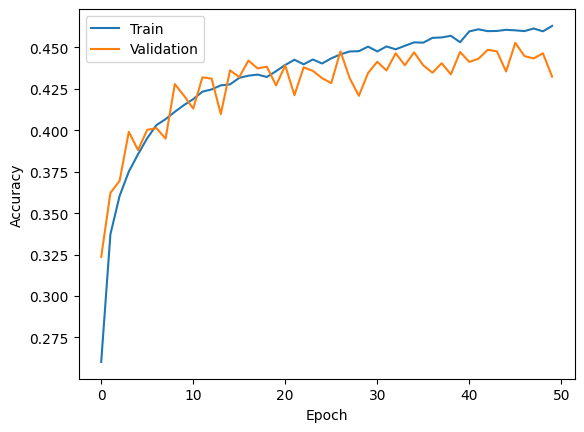

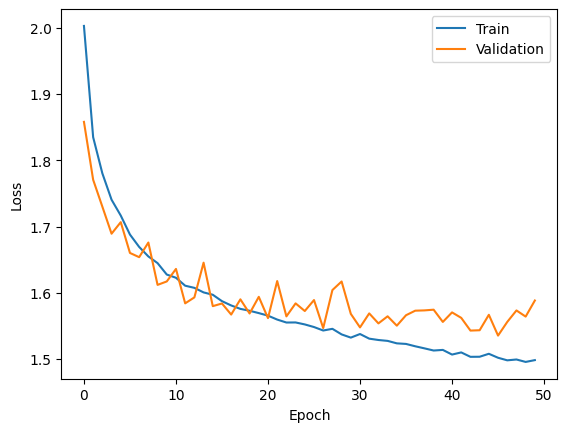

In [ ]:
plt.plot(history_ml.history["accuracy"], label="Train")
plt.plot(history_ml.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
plt.plot(history_ml.history["loss"], label="Train")
plt.plot(history_ml.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [3]:
#DL
model_dl = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Conv2D(64, (3, 3),activation='relu'),
    tf.keras.layers.Conv2D(64, (3, 3),activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3),activation='relu'),
    tf.keras.layers.Conv2D(128, (3, 3),activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(256, (3, 3),activation='relu'),
    tf.keras.layers.Conv2D(256, (3, 3),activation='relu'),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [4]:
model_dl.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

In [5]:
history_dl = model_dl.fit(x_train, y_train, epochs=20,validation_split=0.2)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - accuracy: 0.3597 - loss: 1.7146 - val_accuracy: 0.5227 - val_loss: 1.3174
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 28s 7ms/step - accuracy: 0.5533 - loss: 1.2498 - val_accuracy: 0.5797 - val_loss: 1.1457
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.6326 - loss: 1.0395 - val_accuracy: 0.6383 - val_loss: 1.0047
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.6881 - loss: 0.8958 - val_accuracy: 0.6541 - val_loss: 1.0184
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.7240 - loss: 0.7960 - val_accuracy: 0.7054 - val_loss: 0.8468
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.7545 - loss: 0.7051 - val_accuracy: 0.6919 - val_loss: 0.9219
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.7843 - loss: 0.6275 - val_accuracy: 0.7003 - val_loss: 0.8973
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.8055 - loss: 0.5625

In [6]:
model_dl.evaluate(x_test,  y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7122 - loss: 1.6896


[1.6895642280578613, 0.7121999859809875]

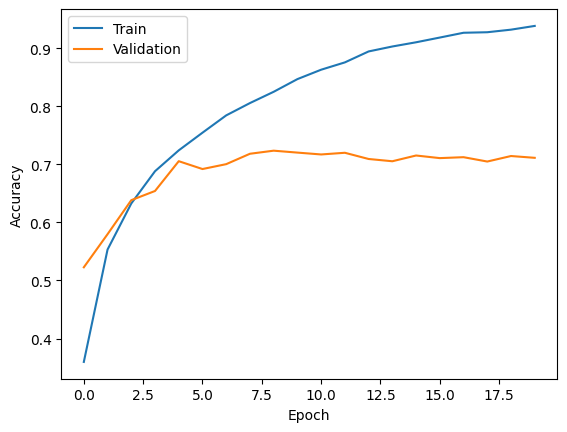

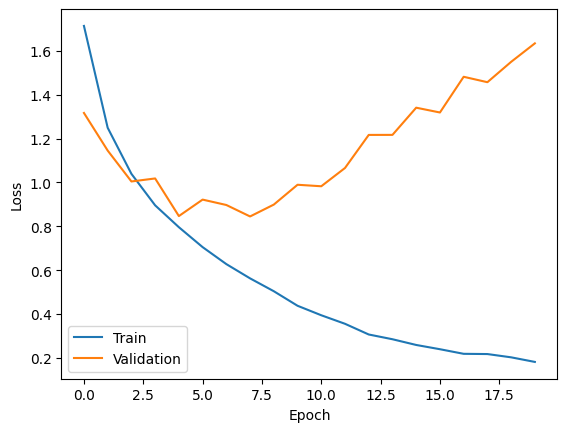

In [7]:
plt.plot(history_dl.history["accuracy"], label="Train")
plt.plot(history_dl.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
plt.plot(history_dl.history["loss"], label="Train")
plt.plot(history_dl.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()